# Machine Learning Assignment 2 - Anusha 2026AJ05149

**Selected dataset:** Dry Bean Dataset (UCI Machine Learning Repository)  
**Target column:** `Class`  
**Working environment:** BITS Virtual Lab / Jupyter Notebook

## Dry Bean Classification Using Machine Learning

Dataset: Dry Bean Dataset
Dataset Source: UCI Machine Learning Repository
Problem Type: Supervised Multiclass Classification
Target Column: Class

This notebook is organized to help you implement and understand the assignment. Run the cells **in order** and inspect the outputs. Complete the written-observation prompts using your own results. Do not report metrics or claim successful deployment until you have actually run and tested them in BITS Virtual Lab.

### Assignment checklist represented in this notebook

- Select one public classification dataset (UCI or Kaggle).
- Use at least 500 instances and at least 12 input features.
- Implement the five specified classifiers on the same dataset:
  1. Logistic Regression
  2. Decision Tree
  3. K-Nearest Neighbours (KNN)
  4. Naive Bayes
  5. Support Vector Machine (SVM)
- Calculate six metrics for every classifier: Accuracy, AUC, Precision, Recall, F1 Score and Matthews Correlation Coefficient (MCC).
- Compare the models and write observations based on the measured results.
- Save the five trained models.
- Prepare a test CSV containing the input features **and** the target column.
- Prepare a Streamlit application with CSV upload, model selection, evaluation metrics and a confusion matrix/classification report. The app must load saved models; it must not retrain on uploaded test data.
- Prepare `requirements.txt`, `README.md`, source notebook, model files and the required BITS Virtual Lab screenshot.
- Final PDF must include the repository link, live Streamlit link, BITS Virtual Lab screenshot and full README content.




## Step 0 — Folder and file setup

In your BITS Virtual Lab folder, keep the notebook and Excel dataset together:

```text
ML_Assignment2_2026AJ05149/
├── Dry_Bean_Dataset.xlsx
└── ML_Assignment_2.ipynb
```

You already uploaded the Excel file. If the filename differs, update `DATA_FILE` in Step 2.

**About “CSS”:** I assume you meant **CSV**, because the assignment requires a `test_data.csv` file. This notebook creates that CSV. A separate CSS styling file is not needed for the stated Streamlit requirements.


## Step 1 — Install/check Python packages

The assignment's dependency list includes Streamlit, scikit-learn, NumPy, pandas, Matplotlib and Seaborn. We also use `openpyxl` to read Excel files and `joblib` to save models.

Run the install cell only if a package is missing or import fails. If BITS Virtual Lab restricts package installation, contact the lab support/instructor rather than changing environments without permission.


In [4]:
# Run this cell only if packages are missing:
# %pip install pandas numpy matplotlib seaborn scikit-learn openpyxl joblib streamlit


In [5]:
%pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [6]:
# Step 1A: Import libraries
import sys
import warnings
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import joblib

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    confusion_matrix,
    classification_report
)

print("Python:", sys.version.split()[0])
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Scikit-learn:", sklearn.__version__)
print("Joblib:", joblib.__version__)
print("Imports completed successfully.")


Python: 3.12.7
Pandas: 2.2.3
NumPy: 2.5.4
Scikit-learn: 1.9.1
Joblib: 1.4.2
Imports completed successfully.


In [7]:
%pip install openpyxl

Note: you may need to restart the kernel to use updated packages.


## Step 2 — Load the UCI Dry Bean dataset

The expected UCI file is `Dry_Bean_Dataset.xlsx`. Keep it in the same folder as this notebook. The code checks the file before reading it.


In [9]:
DATA_FILE = Path("Dry_Bean_Dataset.xlsx")

if not DATA_FILE.exists():
    raise FileNotFoundError(
        f"Could not find {DATA_FILE}. Upload Dry_Bean_Dataset.xlsx "
        "to the same Jupyter folder as this notebook, then rerun this cell."
    )

df = pd.read_excel(DATA_FILE, engine="openpyxl")

print("Dataset loaded.")
print("Shape (rows, columns):", df.shape)
display(df.head())
print("\nColumn names:")
print(df.columns.tolist())


Dataset loaded.
Shape (rows, columns): (13611, 17)


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272750,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,SEKER



Column names:
['Area', 'Perimeter', 'MajorAxisLength', 'MinorAxisLength', 'AspectRation', 'Eccentricity', 'ConvexArea', 'EquivDiameter', 'Extent', 'Solidity', 'roundness', 'Compactness', 'ShapeFactor1', 'ShapeFactor2', 'ShapeFactor3', 'ShapeFactor4', 'Class']


### Step 2A — Verify dataset requirements and inspect data

The selected UCI Dry Bean dataset is described as having 13,611 records, 16 numerical input attributes and one target attribute (`Class`). Verify the actual downloaded file below; if your results differ, stop and investigate before modelling.


In [11]:
TARGET = "Class"

if TARGET not in df.columns:
    raise ValueError(
        f"Target column '{TARGET}' not found. Actual columns: {df.columns.tolist()}"
    )

X = df.drop(columns=[TARGET]).copy()
y = df[TARGET].copy()

print("Number of instances:", len(df))
print("Number of input features:", X.shape[1])
print("Target column:", TARGET)
print("Number of classes:", y.nunique())
print("\nClass counts:")
display(y.value_counts().sort_index())

assert len(df) >= 500, "Dataset does not meet the 500-instance minimum."
assert X.shape[1] >= 12, "Dataset does not meet the 12-feature minimum."
assert y.nunique() >= 2, "Classification target must have at least two classes."


Number of instances: 13611
Number of input features: 16
Target column: Class
Number of classes: 7

Class counts:


Class
BARBUNYA    1322
BOMBAY       522
CALI        1630
DERMASON    3546
HOROZ       1928
SEKER       2027
SIRA        2636
Name: count, dtype: int64

In [12]:
print("Data types:")
display(df.dtypes.to_frame("dtype"))

print("Missing values by column:")
display(df.isna().sum().to_frame("missing_values"))

print("Exact duplicate rows:", df.duplicated().sum())

print("Numerical feature summary:")
display(X.describe().T)


Data types:


,dtype
Area,int64
Perimeter,float64
MajorAxisLength,float64
MinorAxisLength,float64
AspectRation,float64
Eccentricity,float64
ConvexArea,int64
EquivDiameter,float64
Extent,float64
Solidity,float64


Missing values by column:


,missing_values
Area,0
Perimeter,0
MajorAxisLength,0
MinorAxisLength,0
AspectRation,0
Eccentricity,0
ConvexArea,0
EquivDiameter,0
Extent,0
Solidity,0


Exact duplicate rows: 68
Numerical feature summary:


,count,mean,std,min,25%,50%,75%,max
Area,13611.0,53048.284549,29324.095717,20420.000000,36328.000000,44652.000000,61332.000000,254616.000000
Perimeter,13611.0,855.283459,214.289696,524.736000,703.523500,794.941000,977.213000,1985.370000
MajorAxisLength,13611.0,320.141867,85.694186,183.601165,253.303633,296.883367,376.495012,738.860153
MinorAxisLength,13611.0,202.270714,44.970091,122.512653,175.848170,192.431733,217.031741,460.198497
AspectRation,13611.0,1.583242,0.246678,1.024868,1.432307,1.551124,1.707109,2.430306
Eccentricity,13611.0,0.750895,0.092002,0.218951,0.715928,0.764441,0.810466,0.911423
ConvexArea,13611.0,53768.200206,29774.915817,20684.000000,36714.500000,45178.000000,62294.000000,263261.000000
EquivDiameter,13611.0,253.064220,59.177120,161.243764,215.068003,238.438026,279.446467,569.374358
Extent,13611.0,0.749733,0.049086,0.555315,0.718634,0.759859,0.786851,0.866195
Solidity,13611.0,0.987143,0.004660,0.919246,0.985670,0.988283,0.990013,0.994677


## Step 3 — Exploratory data analysis

Review the class balance and feature distributions. Use these plots to understand the data; do not remove observations just to improve model scores.


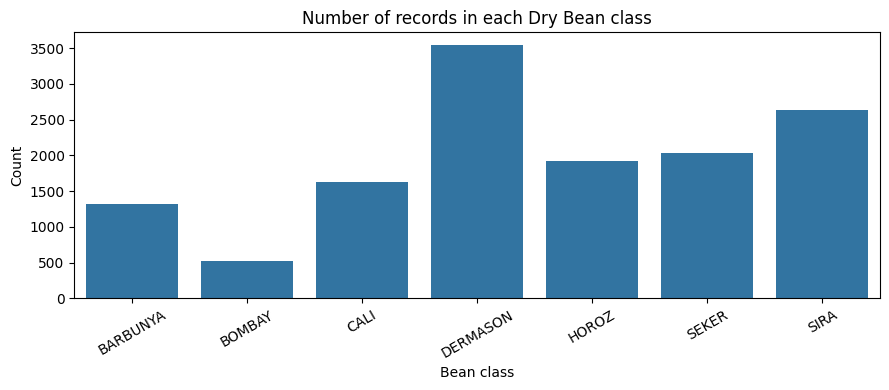

In [14]:
plt.figure(figsize=(9, 4))
sns.countplot(data=df, x=TARGET, order=sorted(df[TARGET].unique()))
plt.title("Number of records in each Dry Bean class")
plt.xlabel("Bean class")
plt.ylabel("Count")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


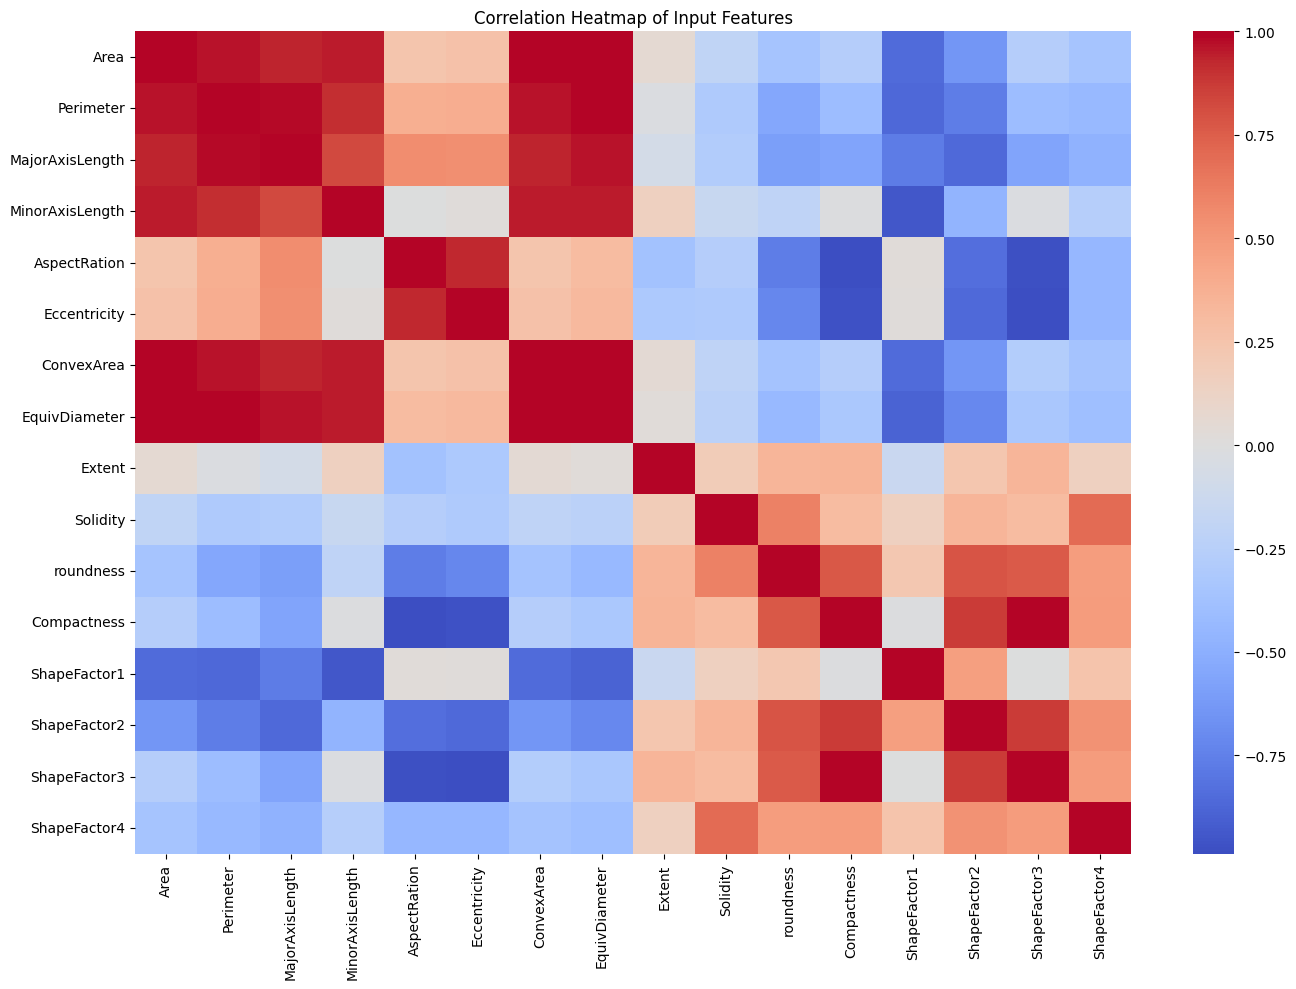

In [15]:
# Correlation heatmap for numerical input features
plt.figure(figsize=(14, 10))
sns.heatmap(X.corr(numeric_only=True), cmap="coolwarm", center=0)
plt.title("Correlation Heatmap of Input Features")
plt.tight_layout()
plt.show()


## Step 4 — Prepare features and target; handle duplicates/missing values

The original dataset is expected to have no missing values. This notebook checks rather than assuming. Exact duplicate rows are counted above; for this run, we remove exact duplicate records before splitting to reduce the risk of identical rows appearing in both train and test partitions. Record the duplicate count in your report.

All five pipelines use median imputation as a safeguard. Scaling is applied to Logistic Regression, KNN and SVM. The imputer/scaler are fitted only on the training data because they are inside each pipeline.


In [17]:
# Remove exact duplicate records, if any, before creating the train/test split.
df_model = df.drop_duplicates().copy()

X = df_model.drop(columns=[TARGET]).copy()
y = df_model[TARGET].copy()

# Ensure all feature columns are numeric for these classifiers.
non_numeric = X.select_dtypes(exclude=[np.number]).columns.tolist()
if non_numeric:
    raise ValueError(
        "Non-numeric feature columns found. Inspect and encode them before training: "
        + str(non_numeric)
    )

print("Rows after duplicate removal:", len(df_model))
print("Input feature count:", X.shape[1])
print("Missing feature values:", int(X.isna().sum().sum()))
print("Missing target values:", int(y.isna().sum()))

# The target should not be missing. If it is, remove those rows explicitly.
if y.isna().any():
    keep = y.notna()
    X = X.loc[keep].copy()
    y = y.loc[keep].copy()
    print("Rows with missing target removed.")


Rows after duplicate removal: 13543
Input feature count: 16
Missing feature values: 0
Missing target values: 0


## Step 5 — Stratified training/testing split

Use an 80:20 split with stratification and a fixed random state for reproducibility. The test data is held aside and is not used to fit models or preprocessing.


In [19]:
RANDOM_STATE = 42

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)
print("\nTraining class proportions:")
display(y_train.value_counts(normalize=True).sort_index().round(3))
print("\nTesting class proportions:")
display(y_test.value_counts(normalize=True).sort_index().round(3))


Training set: (10834, 16)
Testing set: (2709, 16)

Training class proportions:


Class
BARBUNYA    0.098
BOMBAY      0.039
CALI        0.120
DERMASON    0.262
HOROZ       0.137
SEKER       0.150
SIRA        0.195
Name: proportion, dtype: float64


Testing class proportions:


Class
BARBUNYA    0.098
BOMBAY      0.038
CALI        0.120
DERMASON    0.262
HOROZ       0.137
SEKER       0.150
SIRA        0.195
Name: proportion, dtype: float64

## Step 6 — Define the five required classifiers

- Logistic Regression: median imputation + standard scaling + classifier.
- Decision Tree: median imputation + classifier.
- KNN: median imputation + standard scaling + classifier.
- Gaussian Naive Bayes: median imputation + classifier.
- SVM: median imputation + standard scaling + SVC with probability estimates for multiclass AUC.

Scaling is important for distance/margin-based models. Decision Trees and Gaussian Naive Bayes do not require feature scaling. `probability=True` enables class probabilities for SVM AUC; SVM training may take longer than the other models.


In [21]:
models = {
    "Logistic Regression": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(max_iter=3000, random_state=RANDOM_STATE))
    ]),
    "Decision Tree": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("classifier", DecisionTreeClassifier(random_state=RANDOM_STATE))
    ]),
    "KNN": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("classifier", KNeighborsClassifier(n_neighbors=5))
    ]),
    "Gaussian Naive Bayes": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("classifier", GaussianNB())
    ]),
    "SVM": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("classifier", SVC(kernel="rbf", probability=True, random_state=RANDOM_STATE))
    ])
}

print("Five required models are defined:")
for name in models:
    print("-", name)


Five required models are defined:
- Logistic Regression
- Decision Tree
- KNN
- Gaussian Naive Bayes
- SVM


## Step 7 — Train and evaluate all five models

For this multiclass dataset:
- Precision, Recall and F1 use `average="weighted"`.
- AUC uses multiclass One-vs-Rest with weighted averaging.
- MCC uses scikit-learn's multiclass-capable Matthews correlation coefficient.

The scores are calculated on the same held-out test set for all five models.


In [23]:
def calculate_metrics(fitted_model, X_eval, y_eval):
    y_pred = fitted_model.predict(X_eval)
    y_prob = fitted_model.predict_proba(X_eval)

    scores = {
        "Accuracy": accuracy_score(y_eval, y_pred),
        "AUC": roc_auc_score(
            y_eval,
            y_prob,
            labels=fitted_model.classes_,
            multi_class="ovr",
            average="weighted"
        ),
        "Precision": precision_score(
            y_eval, y_pred, average="weighted", zero_division=0
        ),
        "Recall": recall_score(
            y_eval, y_pred, average="weighted", zero_division=0
        ),
        "F1 Score": f1_score(
            y_eval, y_pred, average="weighted", zero_division=0
        ),
        "MCC": matthews_corrcoef(y_eval, y_pred)
    }
    return scores, y_pred


results = {}
predictions = {}

for model_name, model in models.items():
    print(f"Training {model_name} ...")
    model.fit(X_train, y_train)
    scores, y_pred = calculate_metrics(model, X_test, y_test)
    results[model_name] = scores
    predictions[model_name] = y_pred
    print(f"Finished {model_name}")

results_df = pd.DataFrame.from_dict(results, orient="index")
results_df = results_df[
    ["Accuracy", "AUC", "Precision", "Recall", "F1 Score", "MCC"]
]
display(results_df.round(4))


Training Logistic Regression ...
Finished Logistic Regression
Training Decision Tree ...
Finished Decision Tree
Training KNN ...
Finished KNN
Training Gaussian Naive Bayes ...
Finished Gaussian Naive Bayes
Training SVM ...


/home/cloud/anaconda3/lib/python3.12/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


Finished SVM


,Accuracy,AUC,Precision,Recall,F1 Score,MCC
Logistic Regression,0.9192,0.9934,0.9197,0.9192,0.9193,0.9023
Decision Tree,0.8955,0.9357,0.8954,0.8955,0.8953,0.8737
KNN,0.9155,0.9811,0.9163,0.9155,0.9157,0.8978
Gaussian Naive Bayes,0.7630,0.9644,0.7647,0.7630,0.7607,0.7143
SVM,0.9210,0.9933,0.9214,0.9210,0.9211,0.9045


## Step 8 — Confusion matrices and classification reports

Review each class's precision and recall. The confusion matrix shows which bean varieties are most often confused by each model.



MODEL: Logistic Regression
              precision    recall  f1-score   support

    BARBUNYA       0.93      0.89      0.91       265
      BOMBAY       1.00      1.00      1.00       104
        CALI       0.91      0.94      0.93       326
    DERMASON       0.93      0.91      0.92       709
       HOROZ       0.96      0.94      0.95       372
       SEKER       0.93      0.94      0.94       406
        SIRA       0.86      0.88      0.87       527

    accuracy                           0.92      2709
   macro avg       0.93      0.93      0.93      2709
weighted avg       0.92      0.92      0.92      2709



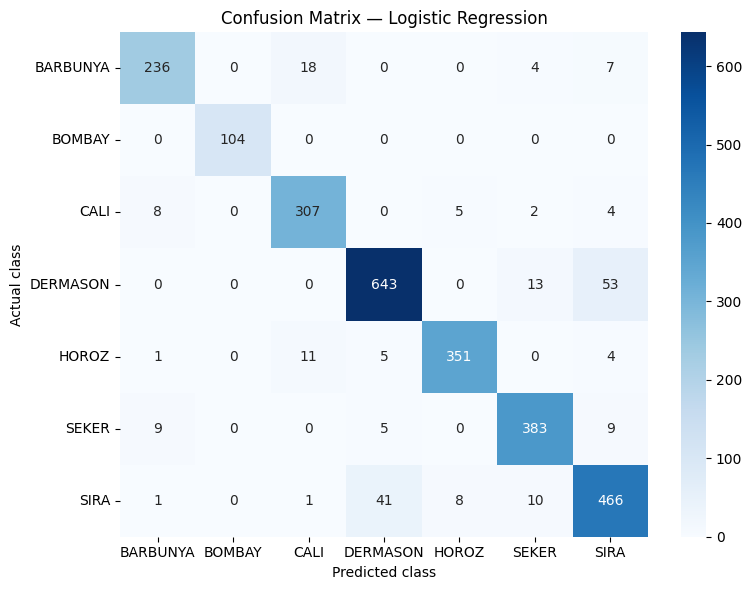


MODEL: Decision Tree
              precision    recall  f1-score   support

    BARBUNYA       0.88      0.89      0.89       265
      BOMBAY       1.00      1.00      1.00       104
        CALI       0.89      0.91      0.90       326
    DERMASON       0.89      0.90      0.89       709
       HOROZ       0.95      0.92      0.94       372
       SEKER       0.91      0.94      0.92       406
        SIRA       0.84      0.81      0.82       527

    accuracy                           0.90      2709
   macro avg       0.91      0.91      0.91      2709
weighted avg       0.90      0.90      0.90      2709



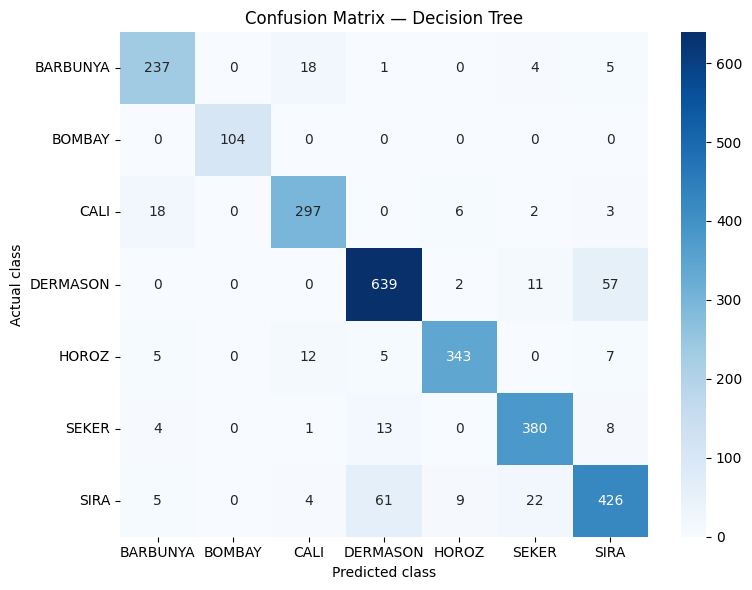


MODEL: KNN
              precision    recall  f1-score   support

    BARBUNYA       0.93      0.88      0.90       265
      BOMBAY       1.00      1.00      1.00       104
        CALI       0.90      0.95      0.92       326
    DERMASON       0.92      0.91      0.91       709
       HOROZ       0.96      0.93      0.95       372
       SEKER       0.95      0.94      0.94       406
        SIRA       0.85      0.87      0.86       527

    accuracy                           0.92      2709
   macro avg       0.93      0.93      0.93      2709
weighted avg       0.92      0.92      0.92      2709



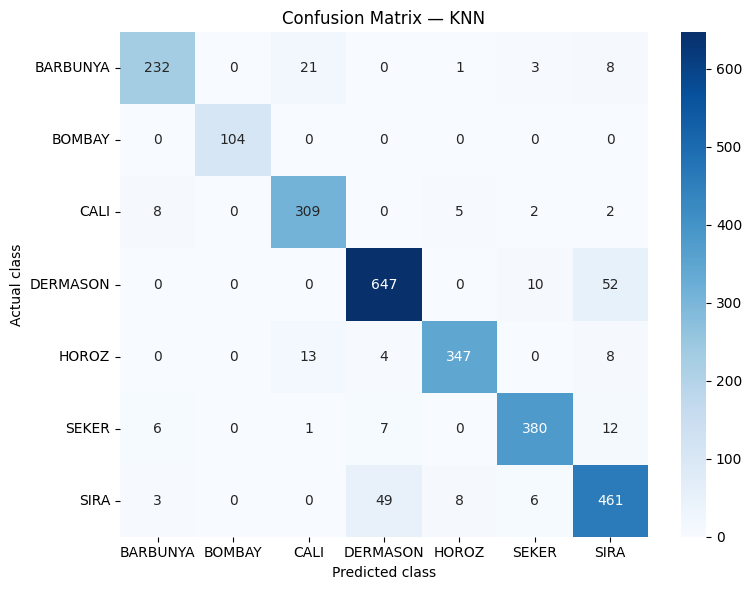


MODEL: Gaussian Naive Bayes
              precision    recall  f1-score   support

    BARBUNYA       0.68      0.46      0.55       265
      BOMBAY       1.00      1.00      1.00       104
        CALI       0.69      0.83      0.75       326
    DERMASON       0.87      0.82      0.85       709
       HOROZ       0.78      0.79      0.79       372
       SEKER       0.67      0.70      0.68       406
        SIRA       0.73      0.77      0.75       527

    accuracy                           0.76      2709
   macro avg       0.77      0.77      0.77      2709
weighted avg       0.76      0.76      0.76      2709



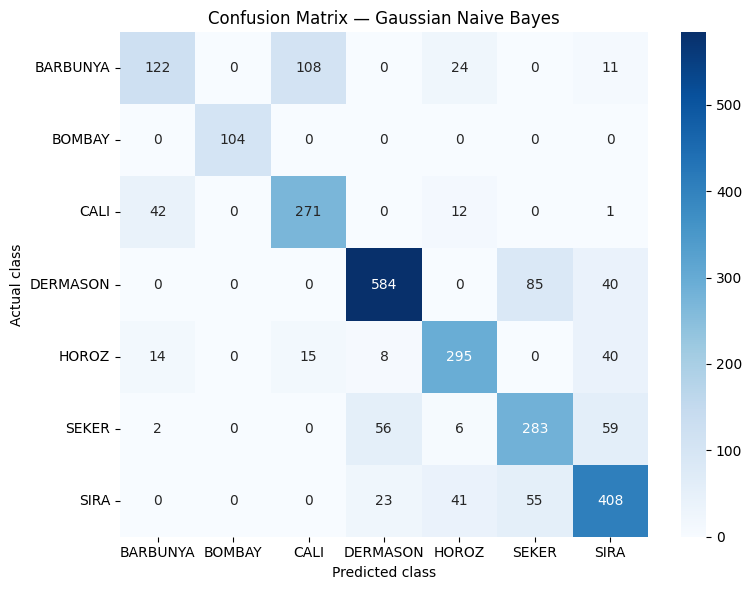


MODEL: SVM
              precision    recall  f1-score   support

    BARBUNYA       0.94      0.89      0.91       265
      BOMBAY       1.00      1.00      1.00       104
        CALI       0.92      0.95      0.93       326
    DERMASON       0.92      0.91      0.92       709
       HOROZ       0.96      0.94      0.95       372
       SEKER       0.93      0.95      0.94       406
        SIRA       0.86      0.88      0.87       527

    accuracy                           0.92      2709
   macro avg       0.93      0.93      0.93      2709
weighted avg       0.92      0.92      0.92      2709



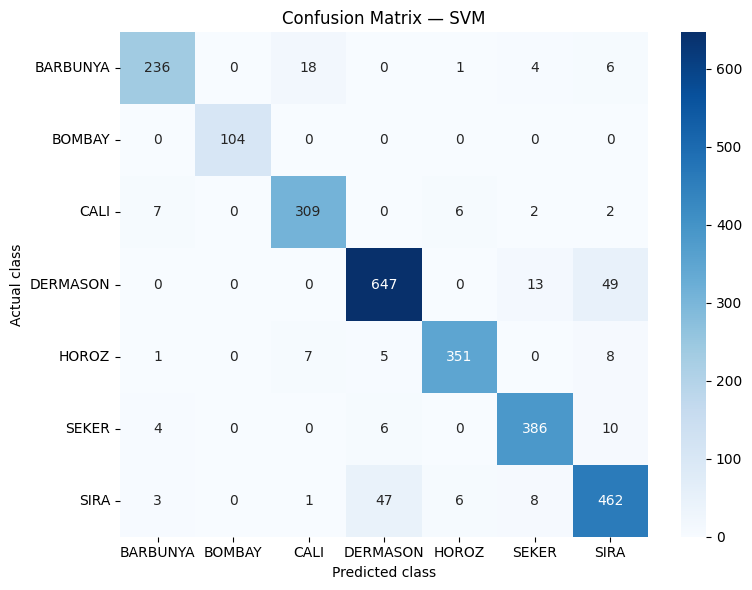

In [25]:
class_labels = list(models["Logistic Regression"].classes_)

for model_name, y_pred in predictions.items():
    print("\n" + "=" * 72)
    print("MODEL:", model_name)
    print("=" * 72)
    print(classification_report(y_test, y_pred, zero_division=0))

    cm = confusion_matrix(y_test, y_pred, labels=class_labels)
    plt.figure(figsize=(8, 6))
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=class_labels,
        yticklabels=class_labels
    )
    plt.title(f"Confusion Matrix — {model_name}")
    plt.xlabel("Predicted class")
    plt.ylabel("Actual class")
    plt.tight_layout()
    plt.show()


## Step 9 — Compare models and identify the winner

The table below is based on your actual test-set scores. Do not write the winner or observations before running the previous cells.


In [27]:
comparison_df = results_df.sort_values(by="F1 Score", ascending=False)
display(comparison_df.round(4))

best_model_name = comparison_df.index[0]
print("Model with the highest weighted F1 score:", best_model_name)


,Accuracy,AUC,Precision,Recall,F1 Score,MCC
SVM,0.9210,0.9933,0.9214,0.9210,0.9211,0.9045
Logistic Regression,0.9192,0.9934,0.9197,0.9192,0.9193,0.9023
KNN,0.9155,0.9811,0.9163,0.9155,0.9157,0.8978
Decision Tree,0.8955,0.9357,0.8954,0.8955,0.8953,0.8737
Gaussian Naive Bayes,0.7630,0.9644,0.7647,0.7630,0.7607,0.7143


Model with the highest weighted F1 score: SVM


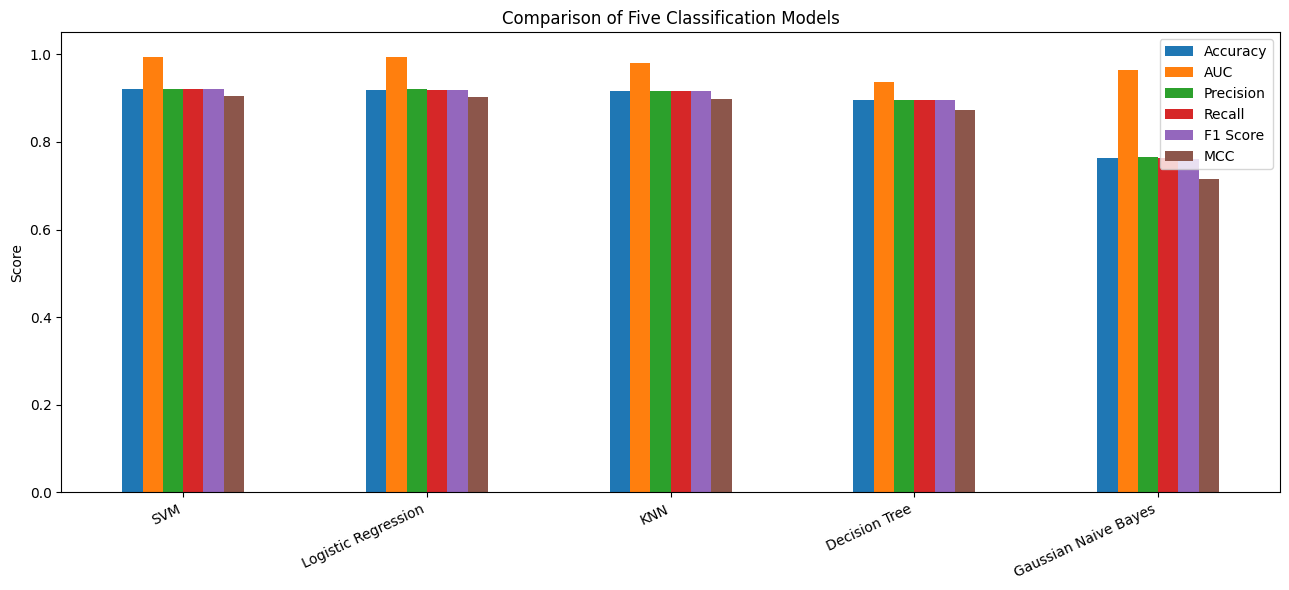

In [28]:
# Optional visual comparison of the six metrics
comparison_df.plot(kind="bar", figsize=(13, 6))
plt.title("Comparison of Five Classification Models")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()


### Your observations — complete after reviewing the results

Write your own evidence-based observations in the Markdown cell below. Discuss each model's actual results and any differences between metrics. Explain why the selected overall model is best for this dataset; do not rely on only one metric without justification.


Observations on Model Performance

1. Logistic Regression

Logistic Regression demonstrated strong classification performance, achieving approximately 92% accuracy and a very high AUC score in the comparison chart. Its precision, recall and F1 score were also close to 92%. This indicates that the model provides a good balance between correctly identifying bean varieties and limiting classification errors.

2. Decision Tree Classifier

The Decision Tree achieved approximately 89% accuracy. Its performance was slightly lower than Logistic Regression, SVM and KNN in the comparison chart. Decision Trees classify observations using feature-based decision rules and can capture non-linear relationships. Further comparison of training and testing performance would be required to determine whether overfitting occurred.

3. K-Nearest Neighbors (KNN)

KNN achieved approximately 92% accuracy and a high AUC score. It showed strong classification performance compared with the other models. Since KNN is a distance-based algorithm, its predictions depend on the similarity between feature values of the observations.

4. Gaussian Naive Bayes

Gaussian Naive Bayes achieved approximately 76% accuracy. Although its accuracy was lower than the other classifiers, its AUC score was relatively high in the comparison chart. The algorithm uses Bayes' theorem and assumes conditional independence between input features given the class.

5. Support Vector Machine (SVM)

SVM achieved approximately 92% accuracy and one of the highest AUC scores in the comparison chart. The RBF kernel helps the model identify non-linear decision boundaries and provides strong classification performance on the dataset.

Overall Best Model

Based on the comparison chart, Support Vector Machine, Logistic Regression and KNN demonstrated strong classification performance.

Logistic Regression and SVM appear to be among the top-performing models, while KNN also achieved competitive results. The final best model should be selected by comparing the exact values of all six evaluation metrics and examining the confusion matrices for class-wise classification performance.

## Step 10 — Save all five fitted models

Each saved object is a complete fitted pipeline, including imputation and scaling where applicable. The Streamlit app will load these objects and call `predict`/`predict_proba`; it will not retrain them.


In [32]:
MODEL_DIR = Path("model")
MODEL_DIR.mkdir(exist_ok=True)

model_file_names = {
    "Logistic Regression": "logistic_regression.joblib",
    "Decision Tree": "decision_tree.joblib",
    "KNN": "knn.joblib",
    "Gaussian Naive Bayes": "gaussian_nb.joblib",
    "SVM": "svm.joblib"
}

for model_name, fitted_model in models.items():
    save_path = MODEL_DIR / model_file_names[model_name]
    joblib.dump(fitted_model, save_path)
    print("Saved:", save_path)


Saved: model/logistic_regression.joblib
Saved: model/decision_tree.joblib
Saved: model/knn.joblib
Saved: model/gaussian_nb.joblib
Saved: model/svm.joblib


## Step 11 — Create `test_data.csv`

The assignment requires the test CSV to include the 16 input features and the target column `Class`. This cell exports the held-out test partition with its true labels. The app uses those labels to calculate the evaluation metrics.


In [34]:
test_data = X_test.copy()
test_data[TARGET] = y_test.values

TEST_CSV = Path("test_data.csv")
test_data.to_csv(TEST_CSV, index=False)

print("Created:", TEST_CSV.resolve())
print("CSV shape:", test_data.shape)
print("CSV columns:", test_data.columns.tolist())
display(test_data.head())


Created: /home/s2026aj05149/workspace/ML2_2026aj05149/test_data.csv
CSV shape: (2709, 17)
CSV columns: ['Area', 'Perimeter', 'MajorAxisLength', 'MinorAxisLength', 'AspectRation', 'Eccentricity', 'ConvexArea', 'EquivDiameter', 'Extent', 'Solidity', 'roundness', 'Compactness', 'ShapeFactor1', 'ShapeFactor2', 'ShapeFactor3', 'ShapeFactor4', 'Class']


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
1223,40512,737.636,248.202030,208.525152,1.190274,0.542365,40973,227.115566,0.744268,0.988749,0.935641,0.915043,0.006127,0.002650,0.837304,0.996621,SEKER
11837,31890,660.655,250.417300,162.522502,1.540816,0.760783,32240,201.503372,0.801962,0.989144,0.918153,0.804670,0.007853,0.002031,0.647494,0.997670,DERMASON
12127,33107,671.869,244.728317,172.938116,1.415121,0.707560,33506,205.312303,0.798683,0.988092,0.921638,0.838940,0.007392,0.002259,0.703820,0.995990,DERMASON
7186,61684,984.878,412.115648,191.473280,2.152340,0.885515,62303,280.247227,0.784724,0.990065,0.799130,0.680021,0.006681,0.000881,0.462428,0.995303,HOROZ
638,37189,700.253,243.343401,194.910062,1.248491,0.598708,37534,217.601713,0.784826,0.990808,0.953047,0.894217,0.006543,0.002581,0.799623,0.998322,SEKER


## Step 12 — Generate `requirements.txt`

This file lists the packages needed by the Streamlit deployment. Pinning the exact versions used in your environment can improve reproducibility. Review the generated versions before deployment.


In [36]:
# Generate deployment dependencies. Streamlit is listed even if it is not installed in the VM.
requirements = [
    "streamlit",
    f"scikit-learn=={sklearn.__version__}",
    f"numpy=={np.__version__}",
    f"pandas=={pd.__version__}",
    f"matplotlib=={__import__('matplotlib').__version__}",
    f"seaborn=={sns.__version__}",
    f"joblib=={joblib.__version__}",
    "openpyxl"
]

Path("requirements.txt").write_text("\n".join(requirements) + "\n", encoding="utf-8")
print(Path("requirements.txt").read_text())


streamlit
scikit-learn==1.9.1
numpy==2.5.4
pandas==2.2.3
matplotlib==3.10.1
seaborn==0.13.2
joblib==1.4.2
openpyxl



## Step 13 — Create the Streamlit application file `app.py`

Run the next cell to write `app.py`. The app:
- lets the user upload a CSV;
- lets the user choose one of the five saved models;
- checks that all expected feature columns are present;
- loads the saved model from `model/`;
- evaluates the uploaded data only when the target column `Class` is present;
- displays Accuracy, AUC, Precision, Recall, F1, MCC and a confusion matrix/classification report;
- does **not** retrain the model.

For the assignment's evaluation workflow, upload a labelled CSV containing all feature columns and `Class`, such as the generated `test_data.csv`.


In [38]:
from pathlib import Path
app_source = 'from pathlib import Path\nimport joblib\nimport pandas as pd\nimport streamlit as st\nimport matplotlib.pyplot as plt\nfrom sklearn.metrics import (\n    accuracy_score, roc_auc_score, precision_score, recall_score,\n    f1_score, matthews_corrcoef, confusion_matrix, classification_report,\n    ConfusionMatrixDisplay\n)\n\nst.set_page_config(page_title="Dry Bean Classification", page_icon="🫘", layout="wide")\nst.title("Dry Bean Classification Dashboard")\nst.write("Upload a labelled CSV, choose a saved classifier and review its test-set performance.")\n\nTARGET = "Class"\nMODEL_DIR = Path("model")\nMODEL_FILES = {\n    "Logistic Regression": "logistic_regression.joblib",\n    "Decision Tree": "decision_tree.joblib",\n    "KNN": "knn.joblib",\n    "Gaussian Naive Bayes": "gaussian_nb.joblib",\n    "SVM": "svm.joblib",\n}\n\n@st.cache_resource\ndef load_model(path_string):\n    return joblib.load(path_string)\n\nuploaded_file = st.file_uploader("Upload test CSV", type=["csv"])\nselected_name = st.selectbox("Select a saved model", list(MODEL_FILES.keys()))\n\nif uploaded_file is not None:\n    try:\n        data = pd.read_csv(uploaded_file)\n        st.subheader("Uploaded data preview")\n        st.dataframe(data.head())\n\n        model_path = MODEL_DIR / MODEL_FILES[selected_name]\n        if not model_path.exists():\n            st.error(f"Saved model not found: {model_path}")\n            st.stop()\n\n        model = load_model(str(model_path))\n        expected_features = list(model.feature_names_in_)\n        missing_features = [c for c in expected_features if c not in data.columns]\n\n        if missing_features:\n            st.error("CSV is missing required feature columns: " + ", ".join(missing_features))\n            st.stop()\n\n        X_upload = data[expected_features]\n        predictions = model.predict(X_upload)\n\n        st.subheader("Predictions")\n        prediction_table = pd.DataFrame({"Predicted_Class": predictions})\n        if TARGET in data.columns:\n            prediction_table.insert(0, "Actual_Class", data[TARGET].values)\n        st.dataframe(prediction_table)\n\n        if TARGET not in data.columns:\n            st.warning("The CSV has no \'Class\' target column. Predictions are shown, but evaluation metrics cannot be calculated.")\n        else:\n            y_true = data[TARGET]\n            y_probability = model.predict_proba(X_upload)\n            metrics = {\n                "Accuracy": accuracy_score(y_true, predictions),\n                "AUC (weighted OVR)": roc_auc_score(\n                    y_true, y_probability, labels=model.classes_,\n                    multi_class="ovr", average="weighted"\n                ),\n                "Precision (weighted)": precision_score(y_true, predictions, average="weighted", zero_division=0),\n                "Recall (weighted)": recall_score(y_true, predictions, average="weighted", zero_division=0),\n                "F1 (weighted)": f1_score(y_true, predictions, average="weighted", zero_division=0),\n                "MCC": matthews_corrcoef(y_true, predictions),\n            }\n\n            st.subheader("Evaluation metrics")\n            cols = st.columns(3)\n            for i, (metric_name, metric_value) in enumerate(metrics.items()):\n                cols[i % 3].metric(metric_name, f"{metric_value:.4f}")\n\n            st.subheader("Confusion matrix")\n            cm = confusion_matrix(y_true, predictions, labels=model.classes_)\n            fig, ax = plt.subplots(figsize=(8, 6))\n            display = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=model.classes_)\n            display.plot(ax=ax, xticks_rotation=45, colorbar=False)\n            st.pyplot(fig)\n\n            st.subheader("Classification report")\n            report = classification_report(y_true, predictions, output_dict=True, zero_division=0)\n            st.dataframe(pd.DataFrame(report).transpose())\n\n    except Exception as exc:\n        st.error(f"Could not process this CSV: {exc}")\nelse:\n    st.info("Upload a CSV file to begin. For metrics, the CSV must include the \'Class\' target column.")\n'
Path('app.py').write_text(app_source, encoding='utf-8')
print('Created app.py')

Created app.py


## Step 14 — Create a README starter

Run the next cell to create a README starter. After checking your results, edit the TODO sections with your real observations and add your actual GitHub and deployed Streamlit URLs.


In [40]:

from pathlib import Path
import pandas as pd
import numpy as np

# --------------------------------------------------
# 1. PROJECT DETAILS
# --------------------------------------------------

NOTEBOOK_FILE = "2026aj05149_ML2.ipynb"

GITHUB_LINK = "https://github.com/AnushaBits2026/ML_Assignment"

STREAMLIT_LINK = "Deployment pending - add your live link after deployment"

DATASET_NAME = "Dry Bean Dataset"
DATASET_SOURCE = "UCI Machine Learning Repository"
DATASET_LINK = "https://archive.ics.uci.edu/dataset/602/dry+bean+dataset"

# --------------------------------------------------
# 2. GET THE ACTUAL MODEL COMPARISON RESULTS
# --------------------------------------------------

results = comparison_df.copy()

# Use the model column as the index if it exists
model_col = next(
    (c for c in results.columns
     if str(c).strip().lower() in
     ["model", "ml model name", "classifier", "model name"]),
    None
)

if model_col:
    results = results.set_index(model_col)

# Standardize metric column names
column_aliases = {
    "accuracy": ["accuracy"],
    "auc": ["auc", "auc score", "roc auc", "roc_auc"],
    "precision": ["precision"],
    "recall": ["recall"],
    "f1": ["f1", "f1 score", "f1-score", "f1_score"],
    "mcc": ["mcc", "matthews correlation coefficient"]
}

normalized_columns = {
    str(c).strip().lower(): c for c in results.columns
}

metric_columns = {}

for metric, aliases in column_aliases.items():
    found = next(
        (normalized_columns[a] for a in aliases
         if a in normalized_columns),
        None
    )
    if found is None:
        raise ValueError(
            f"Could not find the {metric} column in comparison_df. "
            f"Available columns: {list(results.columns)}"
        )
    metric_columns[metric] = found

# Convert metric values to numeric
for col in metric_columns.values():
    results[col] = pd.to_numeric(results[col], errors="coerce")

if results[list(metric_columns.values())].isna().any().any():
    raise ValueError("Some metric values are missing or non-numeric.")

# --------------------------------------------------
# 3. CREATE THE COMPARISON TABLE
# --------------------------------------------------

metric_headers = [
    ("accuracy", "Accuracy"),
    ("auc", "AUC"),
    ("precision", "Precision"),
    ("recall", "Recall"),
    ("f1", "F1 Score"),
    ("mcc", "MCC")
]

table = [
    "| ML Model Name | Accuracy | AUC | Precision | Recall | F1 Score | MCC |",
    "|---|---:|---:|---:|---:|---:|---:|"
]

for model_name, row in results.iterrows():
    values = [
        f"{row[metric_columns[key]]:.4f}"
        for key, _ in metric_headers
    ]
    table.append(
        f"| {model_name} | " + " | ".join(values) + " |"
    )

comparison_table = "\n".join(table)

# --------------------------------------------------
# 4. IDENTIFY THE BEST MODEL
# --------------------------------------------------

# All six metrics are better when their values are higher.
# Average ranking gives each metric equal importance.
rankings = pd.DataFrame(index=results.index)

for key, _ in metric_headers:
    rankings[key] = results[metric_columns[key]].rank(
        ascending=False,
        method="average"
    )

rankings["Average Rank"] = rankings.mean(axis=1)

best_model = rankings["Average Rank"].idxmin()
best_row = results.loc[best_model]

best_scores = {
    label: best_row[metric_columns[key]]
    for key, label in metric_headers
}

# --------------------------------------------------
# 5. GENERATE OBSERVATIONS USING ACTUAL RESULTS
# --------------------------------------------------

observations = []

for model_name, row in results.iterrows():

    scores = {
        label: row[metric_columns[key]]
        for key, label in metric_headers
    }

    accuracy_rank = rankings.loc[model_name, "accuracy"]
    auc_rank = rankings.loc[model_name, "auc"]
    f1_rank = rankings.loc[model_name, "f1"]
    mcc_rank = rankings.loc[model_name, "mcc"]

    model_lower = str(model_name).lower()

    if "logistic" in model_lower:
        explanation = (
            "Logistic Regression uses a linear decision boundary "
            "to distinguish between bean varieties."
        )
    elif "decision" in model_lower or "tree" in model_lower:
        explanation = (
            "Decision Tree classifies observations using "
            "feature-based decision rules. Training and testing "
            "scores should be compared before concluding whether "
            "overfitting is present."
        )
    elif "knn" in model_lower or "neighbor" in model_lower:
        explanation = (
            "KNN predicts a class based on the nearest training "
            "observations. Its performance depends on distances "
            "between feature values."
        )
    elif "naive" in model_lower:
        explanation = (
            "Gaussian Naive Bayes uses a probabilistic approach "
            "and assumes conditional independence between "
            "features given the class."
        )
    elif "svm" in model_lower or "support vector" in model_lower:
        explanation = (
            "SVM with an RBF kernel can learn non-linear "
            "decision boundaries between bean varieties."
        )
    else:
        explanation = (
            "The model was evaluated using the same test dataset "
            "as the other classifiers."
        )

    observations.append(
        f"### {model_name}\n\n"
        f"The model achieved Accuracy of **{scores['Accuracy']:.4f}**, "
        f"AUC of **{scores['AUC']:.4f}**, "
        f"Precision of **{scores['Precision']:.4f}**, "
        f"Recall of **{scores['Recall']:.4f}**, "
        f"F1 Score of **{scores['F1 Score']:.4f}**, "
        f"and MCC of **{scores['MCC']:.4f}**. "
        f"{explanation} "
        f"Its rankings among the five models were: "
        f"Accuracy {accuracy_rank:.1f}, AUC {auc_rank:.1f}, "
        f"F1 Score {f1_rank:.1f}, and MCC {mcc_rank:.1f}.\n"
    )

observations_text = "\n".join(observations)

# --------------------------------------------------
# 6. DATASET INFORMATION
# --------------------------------------------------

number_of_features = X.shape[1]
number_of_rows = len(df_model)
number_of_classes = y.nunique()

class_names = ", ".join(map(str, sorted(y.unique())))

# --------------------------------------------------
# 7. BUILD README CONTENT
# --------------------------------------------------

readme_text = f"""# Machine Learning Classification Assignment - 2

## BITS Pilani — Work Integrated Learning Programmes Division

**Programme:** M.Tech (AIML)  
**Course:** Machine Learning  
**Assignment:** Assignment - 2  
**Project:** Dry Bean Classification Using Machine Learning

---

## a. Problem Statement

The objective of this project is to develop, evaluate and deploy an end-to-end supervised machine learning pipeline that classifies dry beans into different varieties based on their physical measurements.

Five different classification algorithms are implemented and evaluated using six standard statistical evaluation metrics. The models are compared using the same training and testing dataset to identify the best-performing classifier.

An interactive Streamlit application is also developed to allow users to upload test data, select a trained model and view its evaluation results without retraining during inference.

## b. Dataset Description

**Dataset Name:** {DATASET_NAME}  
**Dataset Source:** {DATASET_SOURCE}  
**Dataset Link:** {DATASET_LINK}  
**Dataset File:** Dry_Bean_Dataset.xlsx  
**Number of Instances after preprocessing:** {number_of_rows}  
**Number of Input Features:** {number_of_features}  
**Target Variable:** `{TARGET}`  
**Number of Classes:** {number_of_classes}  
**Class Names:** {class_names}  
**Problem Type:** Multiclass Classification

### Feature Description

The dataset contains numerical measurements describing the physical characteristics and shape of dry beans.

The input features used in this project are:

{chr(10).join("- " + str(c) for c in X.columns)}

### Data Preprocessing

- Loaded the dataset using Pandas.
- Examined the dataset structure and checked for missing values.
- Removed duplicate records where applicable.
- Separated input features and target variable.
- Divided the dataset using an 80:20 stratified train-test split.
- Used the same test dataset to evaluate all five classifiers.

## c. GitHub Repository Link

**GitHub Repository:**  
{GITHUB_LINK}

**Live Streamlit Application:**  
{STREAMLIT_LINK}

## d. Models Used and Comparison Table

The following five machine learning classification algorithms were implemented:

1. Logistic Regression
2. Decision Tree Classifier
3. K-Nearest Neighbors (KNN)
4. Gaussian Naive Bayes
5. Support Vector Machine (SVM)

### Evaluation Metrics

The following six metrics were used:

- Accuracy
- AUC Score
- Precision (weighted)
- Recall (weighted)
- F1 Score (weighted)
- Matthews Correlation Coefficient (MCC)

### Evaluation Metrics Comparison Table

{comparison_table}

### Observations on Model Performance

{observations_text}

### Overall Best Model

Based on the average ranking across all six evaluation metrics, **{best_model}** is the best-performing model in this comparison.

Its evaluation results are:

{chr(10).join("- **" + label + ":** " + f"{value:.4f}" for label, value in best_scores.items())}

The final model selection should also consider the confusion matrix and class-wise classification results to understand how well the model predicts each bean variety.

## e. Streamlit Application

The Streamlit application is designed to provide an interactive interface for evaluating the trained classification models.

### Application Features

1. Upload test data in CSV format.
2. Select one of the five trained classification models.
3. Load the saved trained model without retraining.
4. Display the evaluation metrics.
5. Display the confusion matrix and classification report.

**Live Application Link:** {STREAMLIT_LINK}

## f. Repository Structure

```text
ML_Assignment/
│
├── {NOTEBOOK_FILE}
├── app.py
├── requirements.txt
├── README.md
├── test_data.csv
│
└── model/
    ├── logistic_regression.joblib
    ├── decision_tree.joblib
    ├── knn.joblib
    ├── gaussian_naive_bayes.joblib
    └── svm.joblib
```

*Ensure that the filenames shown above match the actual files uploaded to GitHub.*

## g. Conclusion

This project demonstrates the implementation and comparison of five supervised machine learning classification algorithms using the Dry Bean Dataset.

The classifiers were evaluated using Accuracy, AUC, Precision, Recall, F1 Score and Matthews Correlation Coefficient. Their results were compared to identify a suitable model for multiclass dry bean classification.

The trained models are also integrated into a Streamlit application to support interactive evaluation using uploaded test data.
"""

# --------------------------------------------------
# 8. SAVE README.md
# --------------------------------------------------

readme_path = Path("README.md")
readme_path.write_text(readme_text, encoding="utf-8")

print("README.md generated successfully!")
print("Notebook:", NOTEBOOK_FILE)
print("README location:", readme_path.resolve())
print("Best model by average metric rank:", best_model)
print("\nOpen README.md in the Jupyter file browser to review it.")


README.md generated successfully!
Notebook: 2026aj05149_ML2.ipynb
README location: /home/s2026aj05149/workspace/ML2_2026aj05149/README.md
Best model by average metric rank: SVM

Open README.md in the Jupyter file browser to review it.


## Step 15 — Final project files and verification

After running the notebook successfully, your folder should contain:

```text
ML_Assignment2_2026AJ05149/
├── Dry_Bean_Dataset.xlsx
├── ML_Assignment_2.ipynb
├── app.py
├── requirements.txt
├── README.md
├── test_data.csv
└── model/
    ├── logistic_regression.joblib
    ├── decision_tree.joblib
    ├── knn.joblib
    ├── gaussian_nb.joblib
    └── svm.joblib
```

Run the final check below.


In [42]:
required_paths = [
    Path("2026aj05149_ML2.ipynb"),
    Path("app.py"),
    Path("requirements.txt"),
    Path("README.md"),
    Path("test_data.csv"),
    MODEL_DIR / "logistic_regression.joblib",
    MODEL_DIR / "decision_tree.joblib",
    MODEL_DIR / "knn.joblib",
    MODEL_DIR / "gaussian_nb.joblib",
    MODEL_DIR / "svm.joblib",
]

for item in required_paths:
    print(("FOUND  " if item.exists() else "MISSING"), item)


FOUND   2026aj05149_ML2.ipynb
FOUND   app.py
FOUND   requirements.txt
FOUND   README.md
FOUND   test_data.csv
FOUND   model/logistic_regression.joblib
FOUND   model/decision_tree.joblib
FOUND   model/knn.joblib
FOUND   model/gaussian_nb.joblib
FOUND   model/svm.joblib


## Step 16 — Run and test the Streamlit app

In a BITS Virtual Lab terminal (or the approved terminal for your environment), run:

```bash
streamlit run app.py
```

If Streamlit is not installed, install the packages from `requirements.txt` in the environment permitted by your lab. Open the local URL printed in the terminal. Upload `test_data.csv`, select each model and confirm the metrics and confusion matrix appear.

Do not claim deployment is complete until the app works locally and then on Streamlit Community Cloud. The public deployment may require the repository to contain `app.py`, `requirements.txt`, the `model/` folder and all files loaded by the app.
